# 01. Models at default settings

**Objectives** 
- Explore different types of topic models, ranging from traditional to state-of-the-art approaches, using their default settings.
- Evaluate how each approach behaves on the same posts before any hyperparameter tuning, and identify where each model fails out of the box.
- Compare four models using one random seed, the same 10% sample of the cleaned corpus, and the same evaluation metrics.

| Model | Family | Input |
|---|---|---|
| TF-IDF + NMF | word counts, matrix factorisation | raw text |
| LDA | word counts, probabilistic | spaCy lemmas (nouns, proper nouns, adjectives) |
| BERTopic | embeddings, clustering | raw text |
| KeyNMF (Turftopic) | embeddings, keywords, matrix factorisation | raw text |


Each model section follows the same structure: an overview of how it works, a hypothesis written before running the code, the model fit, the evaluation metrics, the visualisations, and key observations.

In [1]:
%load_ext autoreload
%autoreload 2

import yaml
from pathlib import Path
import logging
from rich import print

import numpy as np
import pandas as pd

from substack_topics.data.explore import safe_view
from substack_topics.models import get_model
from substack_topics.metrics import track_runtime, evaluate_topic_result, build_reference_tokens_and_embeddings
from substack_topics.plots import plot_topic_distributions, inspect_model_topics, plot_model_comparison, compare_top_topics

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s'
)
logging.getLogger("gensim").setLevel(logging.WARNING)
logging.getLogger("httpx").setLevel(logging.WARNING)
logging.getLogger("httpx2").setLevel(logging.WARNING)

## 0. Setup

**The rules that make the comparison fair**

| Setting | Value |
|---|---|
| Posts | a 10% random sample of the cleaned corpus (about 285k), fixed seed |
| Seed | one standard seed (0)|
| Topics | 20 for every model (BERTopic is set to 21 because its outlier topic counts as one)|
| Words scored | each model produces 30 words per topic and the first 10 usable ones are scored |
| Co-occurrence reference | 200,000 posts, tokenised the same way for every model |
| Embedding metrics | computed with a *different* encoder (all-mpnet-base-v2) from the one used to fit BERTopic and KeyNMF |
| Word vectors | GloVe (100 dimensions) |

**The metrics, one per question**

| Metric | Question | Target Direction |
|---|---|---|
| `coherence_c_npmi` | Do a topic's top words appear together in the same posts? | higher |
| `wec` | Are a topic's top words close together in a pretrained word-vector space? | higher |
| `centroid_sim_diff` | Are a topic's posts closer to their centre than random posts would be? | higher |
| `topic_diversity` | Do different topics use different words? | higher |
| `outlier_rate` | How many posts were left unassigned? | lower (though 0 can mean forcing everything in) |
| `largest_topic_relative_%` | What share of assigned posts does the largest topic hold? | lower |
| `largest_topic_absolute_%` | What share of all posts does the largest topic hold? | lower |
| `runtime_m` | How long did one fit take? | lower |

In [23]:
import gensim.downloader as api
wv = api.load("glove-wiki-gigaword-100") 
WORD_VECTORS = "GloVe embeddings (100 dimensions)"

In [3]:
# Setup file paths
CONFIG_FILE = Path("../models.yaml")
CORPUS_FILE = Path("../data/interim/substack_dataset/substack_processed.parquet")

# Set random seed for reproducibility
SEED = 0
SAMPLE_FRACTION = 0.1

# Evaluation settings
N_COHERENCE_REFERENCE_DOCS = 200_000
TOP_N_SCORED = 10
REFERENCE_EMBEDDINGS_MODEL = "all-mpnet-base-v2"
results, metrics = {}, {}

In [4]:
# Load model baseline configurations and the cleaned text corpus
configs = yaml.safe_load(open(CONFIG_FILE))
corpus = pd.read_parquet(CORPUS_FILE).sample(frac=SAMPLE_FRACTION, random_state=SEED)
display(safe_view(corpus).head(3))
texts = corpus["text_col"].tolist()
print(f"Loaded {len(texts)} documents from {CORPUS_FILE}.")

,article_url,publication_domain,category,post_title,subtitle_summary,publish_date,publish_year,text_col,series_key
1104246,https://scrollandstrategy.substack.com/p/why-scroll-and-strategy-is-entering,https://scrollandstrategy.substack.com,Business & Startups,WHY SCROLL & STRATEGY IS ENTERING A NEW SEASON,"FOUNDER REFLECTION ARTICLE | JUNE 28, 2026",2026-06-28 23:00:12,2026,"WHY SCROLL & STRATEGY IS ENTERING A NEW SEASON. FOUNDER REFLECTION ARTICLE | JUNE 28, 2026",why scroll strategy is entering a new season founder reflection article june 0 0
2454498,https://odelflowers.substack.com/p/the-end-of-the-long-journey,https://odelflowers.substack.com,General & Uncategorized,The End of The Long Journey,Ever wondered what the end of our long journey in self-discovery looks like?,2026-06-19 22:43:40,2026,The End of The Long Journey. Ever wondered what the end of our long journey in self-discovery looks like?,the end of the long journey ever wondered what the end of our long journey in self discovery looks like
2382867,https://eshap.substack.com/p/cartographers-log-live-stupid-succession,https://eshap.substack.com,"Culture, Arts & Literature",Cartographer’s Log Live: Stupid Succession,A recording from Evan Shapiro's live video,2026-09-02 17:57:13,2026,Cartographer’s Log Live: Stupid Succession. A recording from Evan Shapiro's live video,cartographer s log live stupid succession a recording from evan shapiro s live video


Loaded 285465 documents from ../data/interim/substack_dataset/substack_processed.parquet.

Build the coherence and embedding reference **once**, so every model is scored against the same posts.

In [5]:
reference = build_reference_tokens_and_embeddings(texts, max_docs=N_COHERENCE_REFERENCE_DOCS, seed=SEED)

2026-11-19 17:52:28,428 - substack_topics.metrics - INFO - Extracted 200000 reference tokenised documents for coherence evaluation.
2026-11-19 17:52:29,419 - substack_topics.metrics - INFO - Built dictionary with 107612 unique tokens for coherence evaluation.
2026-11-19 17:52:29,537 - substack_topics.embeddings - INFO - Loading embeddings from cache: data/interim/embeddings/all-mpnet-base-v2_6f53af5a5e60.npy
2026-11-19 17:52:29,882 - substack_topics.metrics - INFO - Computed embeddings for 200000 reference documents for coherence evaluation.


## 1. TF-IDF + NMF

**What it does:** 
- Builds a TF-IDF matrix of words, then splits it into 20 topics by non-negative matrix factorisation. 
- Fast, uses word counts only, and is the baseline every other model should beat.

**Hypothesis before running:** 
- The topics will be tightly focused on a few similar words, because NMF only sees word counts.

##### Model Baseline Parameters & Fitting

In [6]:
name = "nmf"
with track_runtime() as timer:
    params = configs[name]
    results[name] = get_model(name)(texts, params, SEED)
print(params)
print(results[name].extra)
print(f"Runtime: {timer['runtime_s']:.2f} seconds ({timer['runtime_m']:.2f} minutes)")


2026-11-19 17:52:31,803 - substack_topics.models - INFO - Document-Term (TF-IDF) matrix shape: (285465, 34211)
2026-11-19 17:53:09,047 - substack_topics.models - INFO - NMF Document-Topic (W) matrix shape: (285465, 20)
2026-11-19 17:53:09,087 - substack_topics.models - INFO - Extracted 20 topics with top 30 words each
2026-11-19 17:53:09,099 - substack_topics.models - INFO - Max topic probability for first 5 documents: [0.00421649 0.03889378 0.00335856 0.00029691 0.02006854]
2026-11-19 17:53:09,100 - substack_topics.models - INFO - Document-topic assignments shape: (285465,)


{
    'n_topics': 20,
    'min_df': 5,
    'max_df': 0.5,
    'max_features': 50000,
    'ngram_range': [1, 1],
    'init': 'nndsvda',
    'max_iter': 300,
    'top_n_words': 30
}

{
    'model': NMF(init='nndsvda', max_iter=300, n_components=20, random_state=0),
    'vectorizer': TfidfVectorizer(max_df=0.5, max_features=50000, min_df=5, stop_words='english')
}

Runtime: 39.20 seconds (0.70 minutes)

##### Model Evaluation

In [7]:
metrics[name] = {"model": name, "seed": SEED,
                 "runtime_s": round(timer['runtime_s'], 1), "runtime_m": round(timer['runtime_m'], 1),
                 **evaluate_topic_result(results[name], texts=texts, 
                                         reference=reference, topn=TOP_N_SCORED, 
                                         wv=wv, seed=SEED)}
print(metrics[name])

2026-11-19 17:53:09,202 - substack_topics.metrics - INFO - Calculating coherence scores...
2026-11-19 17:53:13,744 - substack_topics.metrics - INFO - Calculating word embedding coherence...
2026-11-19 17:53:13,747 - substack_topics.metrics - INFO - Calculating centroid similarity...
2026-11-19 17:53:14,383 - substack_topics.metrics - INFO - Calculating silhouette coefficient...


{
    'model': 'nmf',
    'seed': 0,
    'runtime_s': 39.2,
    'runtime_m': 0.7,
    'n_topics': 20,
    'topic_diversity': 0.79,
    'outlier_rate': 0.0,
    'largest_topic_size': 130617,
    'median_topic_size': 7705.0,
    'smallest_topic_size': 5123,
    'largest_topic_relative_%': 45.773,
    'median_topic_relative_%': 2.7,
    'smallest_topic_relative_%': 1.795,
    'largest_topic_absolute_%': 45.756,
    'median_topic_absolute_%': 2.699,
    'smallest_topic_absolute_%': 1.795,
    'n_tiny_topics': 0,
    'coherence_words_expected': 200,
    'coherence_words_found': 193,
    'coherence_word_coverage': 0.965,
    'coherence_n_topics_scored': 20,
    'coherence_c_v': 0.567,
    'coherence_c_npmi': 0.105,
    'wec': 0.478,
    'wec_n_topics_scored': 20,
    'wec_word_coverage': 0.995,
    'wec_per_topic': [
        0.49704623222351074,
        0.5054490566253662,
        0.5088622570037842,
        0.3632875680923462,
        0.48512059450149536,
        0.3723931312561035,
        0.310258150100708,
        0.4545730650424957,
        0.4446934461593628,
        0.4484003186225891,
        0.5475092530250549,
        0.5218651294708252,
        0.5483717322349548,
        0.456290602684021,
        0.5649710893630981,
        0.5890882015228271,
        0.3991225063800812,
        0.6822454333305359,
        0.49911466240882874,
        0.369651198387146
    ],
    'centroid_sim': 0.367,
    'centroid_sim_topic_mean': 0.396,
    'centroid_sim_chance': 0.336,
    'centroid_sim_diff': 0.031,
    'centroid_sim_per_topic': [
        0.32238614559173584,
        0.43935686349868774,
        0.4323624074459076,
        0.3682885766029358,
        0.43905046582221985,
        0.5518068075180054,
        0.41379082202911377,
        0.3729760944843292,
        0.438032329082489,
        0.39360252022743225,
        0.3510916829109192,
        0.3004518151283264,
        0.3464151918888092,
        0.4189341962337494,
        0.31037741899490356,
        0.44251835346221924,
        0.4508358836174011,
        0.3239161968231201,
        0.401100754737854,
        0.39571863412857056
    ],
    'silhouette': -0.036
}

##### Plots

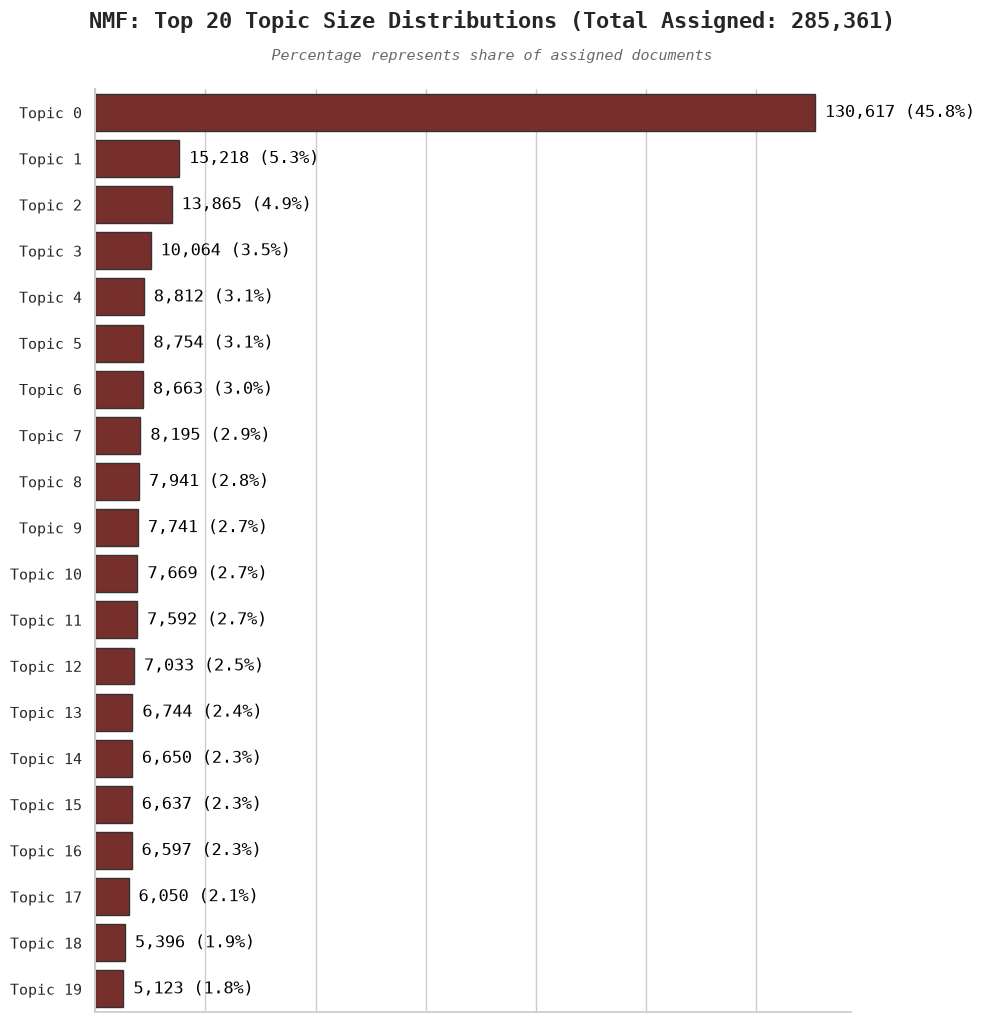

,topic,size,relative_share_%,absolute_share_%,top_words,examples
0,0,130617,45.8,45.8,"people, ve, work, way, make, years, let, art, right, think","Donald Trump is not the first US president to revamp the Monroe Doctrine. In 1954, against a background of rebellion and repression in Puerto Rico, the Eisenhower administration redefined Monroe to ap || Your Body Is Telling the Truth You Won't. Your Symptoms Aren't the Problem—They're the Message Your Body Has Been Trying to Deliver. || Net-Net at 70% NCAV with consistent, growing FCF. Buying back ~2.75% each quarter. Investment portfolio 10x since 2015.. A 'mini Hikari Tsushin' at a deep discount: the diversified investment portfoli"
1,1,15218,5.3,5.3,"2026, september, august, july, newsletter, june, april, weekly, march, update",June Media Roundup. a moody one || 🎯Take Profit Alert: Closing CSP On $HOOD With 64% Of Reward Captured in 2 Days. Friday 9/18/2026 Locking in 64% Gain on HOOD Cash-Secured Put || 🥃 The Whisky Ring. Email originally sent to subscribers on 19th March 2026
2,2,13865,4.9,4.9,"book, writing, read, reading, books, club, review, chapter, write, month","👁️How to Spot a Fraud: Do Kwon's Death Spiral, Pt. 1. More from my next book: Know the scammer. Know thyself. || K-Beauty Services Review Part 1. What I Got Done in Seoul (and Was It Worth It?) || North of the Highway: Something for Everyone. Plus backgammon, a literacy nook, and a puppet show."
3,3,10064,3.5,3.5,"new, york, welcome, moon, happy, city, series, plus, newsletter, music","#02: Continuous Glucose Monitoring - a new performance tool?. A new generation of wearables, originally built to help diabetes sufferers, is gaining traction as a metric for performance, wellness and || Letters from Home—a new series.. Dear Mama, || Above the Waves, Beyond the Runway: China's New Ekranoplan and the Littoral Mobility Equation. A recent video circulating on Chinese social media has captured defense analysts' attention: a large, gre"
4,4,8812,3.1,3.1,"week, weekly, news, 26, 10, friday, fashion, sunday, market, newsletter","Weekly Meal Plan and Workout Schedule. Everything I post is available to everyone - whether you can afford a paid subscription or not. || Phil Collins: ""People would hire me thinking, In a minute he’s going to go DA-DA! DA-DA! DA-DA!"". A vintage transcript from Phil Collins this week, to celebrate his return to view after serious illnes || Letters to my 20s, 30s, 40s, and.... hopefully to my 50s soon. My birthday is next week!"
5,5,8754,3.1,3.1,"ai, use, data, human, future, agents, age, intelligence, tools, building","AI Crypto Digest - November 24th, 2025. Satoshi Stacker, Crypto Banter, & Ivan on Tech || 6x A/B Tests to Digivolve Your Web Header into 2026. Digivolve your header with design trends from 15 leading AI brands. || The Real AI Divide Is Growth Versus Headcount, Not Adoption. An analysis published in The Financial Brand argues that credit unions are splitting into two camps on artificial intelligence."
6,6,8663,3.0,3.0,"year, 2025, happy, old, end, 2024, review, books, january, best","Be Kind to Your Inner Child. You should never speak to an 8-year-old this way || What is and How to Develop a (Http)Controller on Back-End Applications. Responsibilities, information hiding, dependencies, exception handling, logging on exceptions of a Controller || End of Year Momentum, Finally. A wave of new opportunities and what we're learning from them."
7,7,8195,2.9,2.9,"world, cup, war, end, change, real, living, trump, america, place","My Journey Into the Magical World Of Plant Dyes. Part one: how one environmental science course in college changed the trajectory of my life, eventually leading me to quit my corporate job and spend a || I wrote to Pope Leo XIV last November. He wrote me back.. Prior to being elected our new Pope, Cardinal Robert Prevost was head of the Dicastery for Bishops at the Vatican, making recommendations to t || the de-whimisification of disney world. I'm sick and tired o

In [8]:
plot_topic_distributions(results[name].doc_topics, len(results[name].topics), model_name=name)
inspect_model_topics(results[name], texts)

**Observations**
- Co-occurrence coherence shows that the topics are interpretable (c_v of 0.567) and words co-occur more frequently than random chance (c_npmi of 0.105). 
- However, **topic 0 holds about 46% of all posts** and its top words are generic: *people, ve, work, way, make, years*. Every other topic holds between 1.8% and 5.3%.
- Several topics focus on **format and the calendar** rather than subject matter. For example, one consists of month names and years (2026, september, august, july, newsletter), while another centers on weekly cadence (week, weekly, news, friday, newsletter).
- Topic diversity is 0.79. Words such as *newsletter* appear in several topics.

**Key Takeaways:** 
- *ve* is likely from contractions like *I've*, as the default token pattern splits at the apostrophe. With minimal preprocessing, leftovers like this end up in the topic words, along with different forms of the same root word.
- Based on the topic cards, NMF is much more keyword-focused than concept-focused. As a result, many format-based topics are grouped together by common terms like "book", "letter", "podcast" and "video".
- Much more text cleaning is needed to generate truly insightful topics.

## 2. LDA

**What it does:** 
- A probabilistic model that assumes each post is a mix of topics and each topic a distribution over words. 
- Run on lemmatised nouns, proper nouns and adjectives (spaCy).

**Hypothesis before running:** 
- As it relies heavily on document length to establish co-occurrence count, LDA might not perform as well on short text

##### Model Baseline Parameters & Fitting

In [9]:
name = "lda"
with track_runtime() as timer:
    params = configs[name]
    results[name] = get_model(name)(texts, params, SEED)
print(params)
print(results[name].extra)
print(f"Runtime: {timer['runtime_s']:.2f} seconds ({timer['runtime_m']:.2f} minutes)")


2026-11-19 17:56:30,839 - substack_topics.models - INFO - LDA dictionary size: 27067
2026-11-19 17:56:57,984 - substack_topics.models - INFO - Extracted 20 topics with top 30 words each
2026-11-19 17:57:06,424 - substack_topics.models - INFO - Max topic probability for first 5 documents: [0.30504453 0.26251006 0.40506616 0.34443399 0.38106477]
2026-11-19 17:57:06,426 - substack_topics.models - INFO - Document-topic assignments shape: (285465,)


{
    'n_topics': 20,
    'passes': 5,
    'alpha': 'symmetric',
    'eta': None,
    'workers': 2,
    'add_bigrams': False,
    'no_below': 5,
    'no_above': 0.5,
    'top_n_words': 30
}

{
    'model': <gensim.models.ldamulticore.LdaMulticore object at 0x33d10af60>,
    'dictionary': <gensim.corpora.dictionary.Dictionary object at 0x32f4b7e90>
}

Runtime: 229.70 seconds (3.80 minutes)

##### Model Evaluation

In [10]:
metrics[name] = {"model": name, "seed": SEED,
                 "runtime_s": round(timer['runtime_s'], 1), "runtime_m": round(timer['runtime_m'], 1),
                 **evaluate_topic_result(results[name], texts=texts, 
                                         reference=reference, topn=TOP_N_SCORED, 
                                         wv=wv, seed=SEED)}
print(metrics[name])

2026-11-19 17:57:06,588 - substack_topics.metrics - INFO - Calculating coherence scores...
2026-11-19 17:57:10,859 - substack_topics.metrics - INFO - Calculating word embedding coherence...
2026-11-19 17:57:10,863 - substack_topics.metrics - INFO - Calculating centroid similarity...
2026-11-19 17:57:11,395 - substack_topics.metrics - INFO - Calculating silhouette coefficient...


{
    'model': 'lda',
    'seed': 0,
    'runtime_s': 229.7,
    'runtime_m': 3.8,
    'n_topics': 20,
    'topic_diversity': 0.975,
    'outlier_rate': 0.005,
    'largest_topic_size': 28961,
    'median_topic_size': 12310.5,
    'smallest_topic_size': 7118,
    'largest_topic_relative_%': 10.192,
    'median_topic_relative_%': 4.332,
    'smallest_topic_relative_%': 2.505,
    'largest_topic_absolute_%': 10.145,
    'median_topic_absolute_%': 4.312,
    'smallest_topic_absolute_%': 2.493,
    'n_tiny_topics': 0,
    'coherence_words_expected': 200,
    'coherence_words_found': 197,
    'coherence_word_coverage': 0.985,
    'coherence_n_topics_scored': 20,
    'coherence_c_v': 0.478,
    'coherence_c_npmi': 0.062,
    'wec': 0.434,
    'wec_n_topics_scored': 20,
    'wec_word_coverage': 0.995,
    'wec_per_topic': [
        0.4405389130115509,
        0.6205412745475769,
        0.45017269253730774,
        0.500840425491333,
        0.4828203022480011,
        0.4635317623615265,
        0.4107975363731384,
        0.4384140968322754,
        0.37638211250305176,
        0.33318668603897095,
        0.5200617909431458,
        0.5098413825035095,
        0.3257899880409241,
        0.4413214325904846,
        0.4017084836959839,
        0.38077396154403687,
        0.48255106806755066,
        0.37328189611434937,
        0.37532171607017517,
        0.3544507324695587
    ],
    'centroid_sim': 0.365,
    'centroid_sim_topic_mean': 0.356,
    'centroid_sim_chance': 0.336,
    'centroid_sim_diff': 0.029,
    'centroid_sim_per_topic': [
        0.38605985045433044,
        0.3631368577480316,
        0.40396398305892944,
        0.39609289169311523,
        0.4062598645687103,
        0.3545263111591339,
        0.38494977355003357,
        0.3718304932117462,
        0.3706270158290863,
        0.3263222873210907,
        0.319135844707489,
        0.34650999307632446,
        0.35582107305526733,
        0.3177913725376129,
        0.3451322317123413,
        0.34144484996795654,
        0.34463241696357727,
        0.33073967695236206,
        0.3293322026729584,
        0.32355281710624695
    ],
    'silhouette': -0.019
}

##### Plots

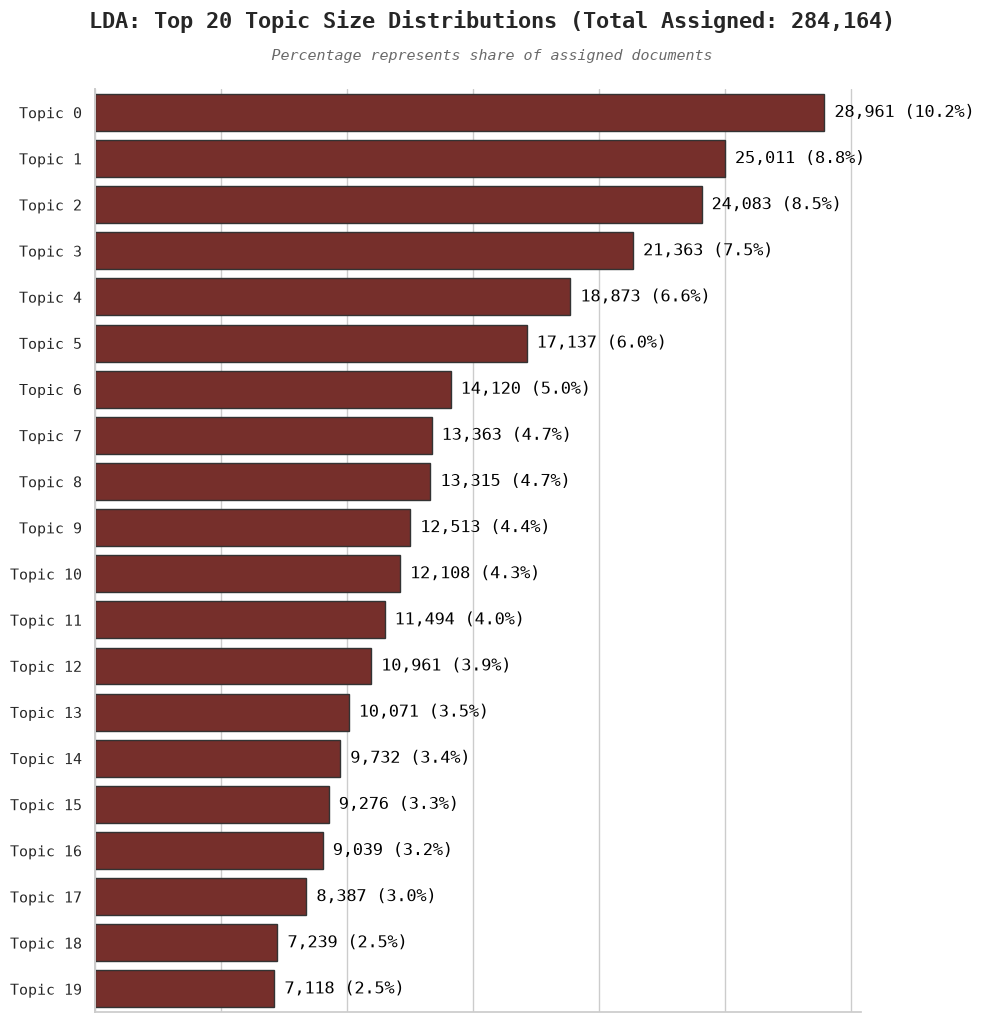

,topic,size,relative_share_%,absolute_share_%,top_words,examples
0,0,28961,10.2,10.1,"ai, business, social, future, system, company, human, product, tech, strategy","How to slow down AI without crashing the economy. Paulo Carvão argues AI firms may slow investment not for safety, but because unsustainable data-center spending demands returns, regardless of existen || Fisk University Receives $4M Federal Grant to Expand Justice Propulsion Lab. Fisk University secured a $4 million federal grant from the U.S. Department of Education's Fund for the Improvement of Post || Welcome to CryptoCharity. Your Guide to Impactful Giving in the Digital Age"
1,1,25011,8.8,8.8,"year, thing, good, week, new, old, bad, time, happy, lot","It's my birthday!. On the best of 2025 and a how-to for celebrating today || COLLAPSE FEEDS COLLAPSE. CAN REPAIR FEED REPAIR?. Repair has to move through personal, institutional, and civic levels because collapse is moving through all three. || Bluegrass and Blues in NYC. Flatt & Scruggs at Carnegie Hall, the Even Dozen Jug Band, the Blues Project, Kinky Friedman in Greenwich Village, and more!"
2,2,24083,8.5,8.4,"life, god, chapter, child, heart, truth, family, way, light, joy","The Kintsugi Tablecloth. Acknowledging the imperfection of life || Chapter Five--Leaving the Faith of our Fathers: a Lifetime Journey. Life and Death in the Family || The Hidden Peptide That’s Fixing Chronic Inflammation When Nothing Else Works. Calm Inflammation, Fix Your Gut, Balance Immunity: The VIP Peptide Deep Dive"
3,3,21363,7.5,7.5,"day, book, post, new, substack, writing, morning, reading, club, writer","Dear Diary, I Think I’m Lost. The world tells me I can be anything, yet not how to be myself. It shows me everything I can become, and in doing so I abandon who I already am. || June 2026. Phoenix and Menlo Park || soak up the sun 101: our end of summer bucket list. put the PSL down <3"
4,4,18873,6.6,6.6,"summer, newsletter, season, week, weekly, edition, news, game, july, september","My Predictions for New York Fashion Week - September 2025. Here we go again! || Nowism - Edition 38. So how can companies really transform || HUGS AND SPIT KISSES FOR ALAN & MARTY: EVERYTHING BUT THE RIVER. Our Guide to Paradise - Week of June 1, 2026"
5,5,17137,6.0,6.0,"new, city, trump, party, public, political, law, government, york, class","🛠 Welcome to Your Citizens Toolbox: Making Public Comments. 🗣 The Essentials: Your Public-Comment Playbook for Speaking at a County Commission Meeting || Navigating Nonprofit Change: Building Stronger Communication. A critical email prompted a transformative shift for Emerald Support Services, underscoring communication and emotional support in managin || We Were Told to Hate Paul Reubens and Refused to Listen. Society refused to understand Pee-wee, so it tried to destroy an innocent man's life."
6,6,14120,5.0,4.9,"art, work, power, room, reality, fear, voice, beauty, john, quiet","‘We <3 the Art’ Results. With more than 1.2M OP being rewarded to 188 artists, it's the largest onchain art contest ever. || When Did We Stop Allowing People to Be Human?. An essay on mistakes, modern culture, and why I wonder if we've confused being human with being good. || Longevity and transience. 長寿と儚さ"
7,7,13363,4.7,4.7,"love, woman, man, friend, health, letter, space, relationship, dear, real","Woman. The allure of a woman for me lies not in the way she sways her hips but in knowing she will sway them only for me. || Built on Bach Listening Party. Hey people… Just a quick note. || Climate Engineered Drought, Heat Dome & Wildfires – Dane Wigington. The US Is in Real Trouble and We Are Wise to Prepare"
8,8,13315,4.7,4.7,"self, body, poem, video, school, mind, live, creative, kid, point","Cookies, Privacy, and the Naughty List: A Guide to Understanding Internet Cookies and Your Rights. Unwrapping Internet Cookies: What They Are, Why They Matter, and How to Take Back Control || NASA’s UAP Efforts: the hope of 2023 vs. the real

In [11]:
plot_topic_distributions(results[name].doc_topics, len(results[name].topics), model_name=name)
inspect_model_topics(results[name], texts)

**Observations:**
- Topic sizes are relatively even (about 2.5% to 10% of posts), and only 0.5% of posts are unassigned (posts with no words left after filtering).
- Topics are less format-based and group related concepts together. For example, one topic includes AI, business, and future, while another covers Trump, political, government, and law, though a calendar topic of month names still remains.
- Compared to NMF, it has a lower co-occurrence coherence (c_v of 0.477 and c_npmi of 0.050) but a much higher topic diversity score of 0.975.

**Key Takeaways:** 
- The topics are more engaging and focus on actual subject matter rather than format, especially compared to NMF.
- This approach is useful for getting a high-level overview of potential topics.

## 3. BERTopic

**What it does:** 
- Embeds each post with a sentence encoder (all-MiniLM-L6-v2), reduces dimensions with UMAP, clusters with HDBSCAN, and labels clusters with c-TF-IDF words. 
- Posts that fit no cluster become outliers (-1). 
- It started with 439 clusters and was merged down to 20 plus the outlier topic.

**Hypothesis before running:** 
- Will produce the highest semantic clustering quality, grouping documents using varied vocabulary.
- However, it might generate a high outlier rate on short titles.

##### Model Baseline Parameters & Fitting

In [12]:
name = "bertopic"
with track_runtime() as timer:
    params = configs[name]
    results[name] = get_model(name)(texts, params, SEED)
print(params)
print(results[name].extra)
print(f"Runtime: {timer['runtime_s']:.2f} seconds ({timer['runtime_m']:.2f} minutes)")


W1119 17:57:19.022000 57916 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
2026-11-19 17:57:20,110 - substack_topics.embeddings - INFO - Loading embeddings from cache: data/interim/embeddings/all-MiniLM-L6-v2_7300e3c35901.npy
2026-11-19 17:57:20,321 - substack_topics.models - INFO - Computed embeddings for 285465 documents
2026-11-19 17:57:20,321 - substack_topics.models - INFO - Embedding dimension: 384
2026-11-19 17:57:20,422 - sentence_transformers.base.model - INFO - No device provided, using mps
2026-11-19 17:57:20,707 - sentence_transformers.base.model - INFO - Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-11-19 17:57:21,734 - huggingface_hub.utils._http - WARNING - Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-11-19 17:57:22,084 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-19 17:59:38,928 - BERTopic - Dimensionality - Completed ✓
2026-11-19 17:59:38,932 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-19 17:59:52,506 - BERTopic - Cluster - Completed ✓
2026-11-19 17:59:52,507 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-11-19 17:59:54,450 - BERTopic - Representation - Completed ✓
2026-11-19 17:59:54,451 - BERTopic - Topic reduction - Reducing number of topics
2026-11-19 17:59:54,530 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-19 17:59:55,990 - BERTopic - Representation - Completed ✓
2026-11-19 17:59:56,000 - BERTopic - Topic reduction - Reduc

{
    'embedding_model': 'all-MiniLM-L6-v2',
    'umap_n_neighbors': 15,
    'umap_n_components': 5,
    'min_cluster_size': 50,
    'min_samples': None,
    'ngram_range': [1, 1],
    'min_df': 5,
    'nr_topics': 21,
    'top_n_words': 30
}

{
    'model': <bertopic._bertopic.BERTopic object at 0x332bd7b30>,
    'embeddings': array([[-0.03899967,  0.06810243,  0.04152402, ..., -0.08996416,
         0.07284127, -0.06869785],
       [ 0.02494077, -0.04663112,  0.07162037, ..., -0.0194978 ,
        -0.10699917,  0.03809658],
       [ 0.0100943 , -0.07975452,  0.03040724, ...,  0.00354084,
        -0.00271474,  0.0665968 ],
       ...,
       [ 0.00790889, -0.00048017, -0.02065147, ..., -0.04163844,
        -0.1167265 , -0.0073776 ],
       [-0.02154785, -0.06999469,  0.02790902, ..., -0.05644587,
        -0.02357819,  0.02436798],
       [-0.02388082,  0.05815395,  0.10066855, ...,  0.07369115,
        -0.07539161,  0.00382334]], shape=(285465, 384), dtype=float32)
}

Runtime: 162.60 seconds (2.70 minutes)

##### Model Evaluation

In [13]:
metrics[name] = {"model": name, "seed": SEED,
                 "runtime_s": round(timer['runtime_s'], 1), "runtime_m": round(timer['runtime_m'], 1),
                 **evaluate_topic_result(results[name], texts=texts, 
                                         reference=reference, topn=TOP_N_SCORED, 
                                         wv=wv, seed=SEED)}
print(metrics[name])

2026-11-19 17:59:56,173 - substack_topics.metrics - INFO - Calculating coherence scores...
2026-11-19 17:59:59,670 - substack_topics.metrics - INFO - Calculating word embedding coherence...
2026-11-19 17:59:59,695 - substack_topics.metrics - INFO - Calculating centroid similarity...
2026-11-19 18:00:00,042 - substack_topics.metrics - INFO - Calculating silhouette coefficient...


{
    'model': 'bertopic',
    'seed': 0,
    'runtime_s': 162.6,
    'runtime_m': 2.7,
    'n_topics': 20,
    'topic_diversity': 0.955,
    'outlier_rate': 0.538,
    'largest_topic_size': 28644,
    'median_topic_size': 3812.0,
    'smallest_topic_size': 156,
    'largest_topic_relative_%': 21.732,
    'median_topic_relative_%': 2.892,
    'smallest_topic_relative_%': 0.118,
    'largest_topic_absolute_%': 10.034,
    'median_topic_absolute_%': 1.335,
    'smallest_topic_absolute_%': 0.055,
    'n_tiny_topics': 0,
    'coherence_words_expected': 200,
    'coherence_words_found': 197,
    'coherence_word_coverage': 0.985,
    'coherence_n_topics_scored': 20,
    'coherence_c_v': 0.484,
    'coherence_c_npmi': 0.07,
    'wec': 0.393,
    'wec_n_topics_scored': 20,
    'wec_word_coverage': 0.985,
    'wec_per_topic': [
        0.40261778235435486,
        0.2744590938091278,
        0.33017340302467346,
        0.5497223138809204,
        0.4003795087337494,
        0.5418037176132202,
        0.26587435603141785,
        0.39056187868118286,
        0.4739648997783661,
        0.594096302986145,
        0.5042182207107544,
        0.2366364598274231,
        0.41675931215286255,
        0.3628956973552704,
        0.4095657765865326,
        0.31061482429504395,
        0.4060758352279663,
        0.22858966886997223,
        0.39979273080825806,
        0.3601056933403015
    ],
    'centroid_sim': 0.417,
    'centroid_sim_topic_mean': 0.456,
    'centroid_sim_chance': 0.331,
    'centroid_sim_diff': 0.086,
    'centroid_sim_per_topic': [
        0.38435986638069153,
        0.3875025808811188,
        0.4082376956939697,
        0.4441136419773102,
        0.4151613712310791,
        0.43324393033981323,
        0.44668519496917725,
        0.548383891582489,
        0.38653746247291565,
        0.4046690762042999,
        0.4561783969402313,
        0.43936413526535034,
        0.48392021656036377,
        0.45086294412612915,
        0.4932752549648285,
        0.4936617314815521,
        0.5030391216278076,
        0.47494861483573914,
        0.5525972843170166,
        0.5034217238426208
    ],
    'silhouette': 0.009
}

##### Plots

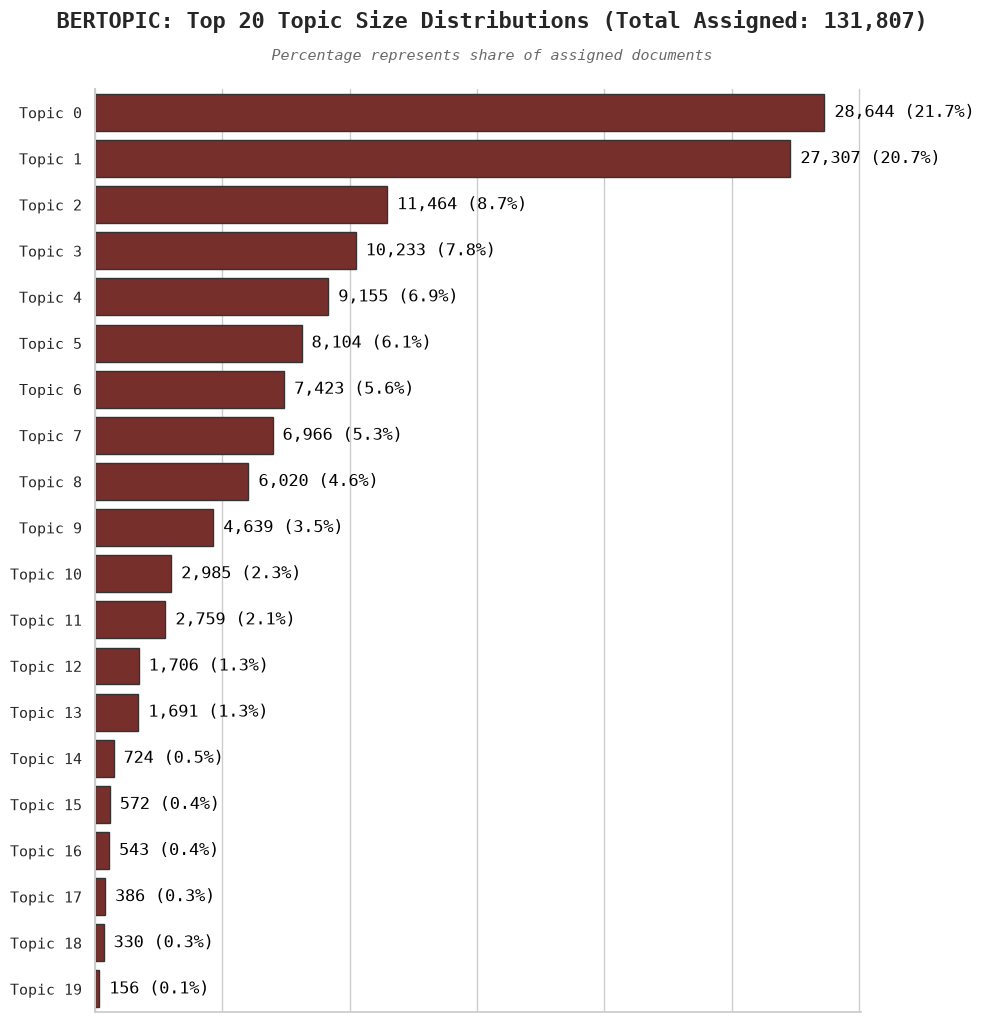

,topic,size,relative_share_%,absolute_share_%,top_words,examples
0,0,28644,21.7,10.0,"poem, episode, podcast, music, moon, new, live, poetry, recording, video",Gracie and the Bird. A short story || Bodies of Water. drawing with a philosopher || Tango in the Desert | Dogs in hammocks. 4~ Navigations: How sixty-five 5th graders changed everything for the better.
1,1,27307,20.7,9.6,"art, life, love, 2026, time, mother, grief, 2025, don, like",why I downsized... and got a fucking grip. me vs. imposter syndrome (I'm losing) || Life and death is in the power of the tongue. Angry words are true thoughts. We should be careful about speaking them. || Love Letters to the World. Why We Still Need to Believe In Love
2,2,11464,8.7,4.0,"iran, war, israel, black, trump, ukraine, women, russia, gaza, election","US Strikes Iran and Still, Dinner Must Be Made. C.S. Lewis wrote about moles and it got me thinking. || The Pornification of Our Culture (Part 2). How It's Affecting Us & Reshaping Us (Especially Young Men) || The Real War: Surviving Convergence, Navigating Unconventional Warfare - Defending The Human Domain. Follow the Science & Technology, A Sense-Making Mission In Defense of Humanity"
3,3,10233,7.8,3.6,"recipe, food, wine, chicken, salad, coffee, recipes, cake, dinner, meal","Life After Butchery. Talking ""Meat and Meaning"" on the Enlightened Omnivore Podcast || I’m Putting the Mac in Risotto: Sunday Night Pasta Programming. Stir your risotto once, twice and move on! + why Carnaroli rice is THE chosen rice || The Story of Learning to Feed Myself. On mystery, misdiagnosis, and macaroni and cheese"
4,4,9155,6.9,3.2,"substack, newsletter, writing, book, books, media, social, read, write, new","The Arc Fall.. Cover Reveal! || Rachel's Recs 6/18/26 🏀 🧫. A bit of housekeeping: I'll be taking the month of July off from the newsletter. || [Podcast] Writing Masterclass with Jane Rosenzweig, Director of the Writing Center, Harvard College [Free Excerpts]. Practical writing strategies distilled from 20-plus years of teaching thousands of"
5,5,8104,6.1,2.8,"christmas, birthday, year, summer, letter, day, happy, new, love, week",Future/ A Letter to You. Maybe I wasn't meant to have a direct relationship with you. || January has ended and it was all worth it.. January has ended like any other month but this month was special. || I'm a walking eye!. Not every day should be workshop day
6,6,7423,5.6,2.6,"market, crypto, bitcoin, money, climate, portfolio, trading, canada, stock, stocks","The false allure of regenerative agriculture. Big government, big foundations and big-name celebrities get behind a sketchy idea || Some reflections on Berkshire Hathaway in 2020. I tend to do most of my valuation updates on Berkshire after the annual results come out, but I register thoughts along the way, as most of you probably || #168 🔧 How To Fix A CEO. There are different types of CEOs: Robot CEO, Perfectionist CEO, People Pleaser CEO, Laissez Faire CEO, Micromanager CEO, and Ready, Fire, Aim CEO."
7,7,6966,5.3,2.4,"ai, data, intelligence, agents, artificial, human, agent, use, work, new",Fait accompli: PCAOB now in the Big 4 audit inspection feel-good business. The transformation of the U.S. public audit regulator into the Big 4's helpmate and cover story producer is full-steam ahead. || Skyfall: How Tech Workers Survive and Thrive in an AI Era. When will AI replace us? || Why Would Anyone Object to Digital ID?. Here's the Truth They Don't Want You to See...
8,8,6020,4.6,2.1,"china, paris, india, japan, travel, chinese, africa, new, italy, france",The Sicilian seaside town of Ortigia. A farmers market by the sea and famous panini master || An update from Spain ❤️. How we're doing as we start our 2nd year living abroad... || 72 Ways to Notice Where You Live. What the calendar gets wrong and what we can learn from a centuries-old Japanese practice
9,9,4639,3.5,1.6,"game, football, cup, season, league, week, nfl, baseball, nba, world","Who are Muntal Bost?. A 

In [14]:
plot_topic_distributions(results[name].doc_topics, len(results[name].topics), model_name=name)
inspect_model_topics(results[name], texts)

**Observations:**
- **54% of posts get no topic.** 6 of the 20 topics each cover under 1% of all **classified** posts. 
- When BERTopic reduces the topics down to the requested number of topics, **outlier topic** (-1) is included in the output
- All evaluation metrics are calculated on 46% of posts that were assigned, which are the easier ones to group.
- It has a higher centroid similarity differences (centroid_sim_diff of 0.086), meaning the clusters are tighter, though its word-embedding coherence is lower (0.393).
- Topics are more concrete: 
    - Specific subjects such as a war and politics topic (*iran, war, israel, trump, ukraine*), a food topic (*recipe, food, wine, chicken*), a money topic (*market, crypto, bitcoin, money*). 
    - There are also format topics (*poem, episode, podcast, music*) and broad ones (*art, life, love, grief*). 

**Key Takeaways:** 
- The topics focus on semantic meaning and has a nice mix of broad and niche themes.
- Compared to NMF and LDA, the topic keywords for each topic are much more specific instead of just common, everyday English words.
- The example posts for a cluster genuinely match the topic's meaning, even if they do not use the exact topic keyword.
    - For example (Topic 9 - Sports): The top keywords are general sports words (*game, football, cup, season, league, week, nfl, baseball, nba, world*). None of the example posts actually use those words. Instead, they talk about specific teams and people (like "Who are Muntal Bost?. A Team Profile", "What Does Leveling Up Look Like For TheCommanders Against Dallas?", and "A Jogging Team: Celtic’s Ibrox Capitulation").
- This is super helpful for topics with many different names and terms (like sports teams, players and coaches). With NMF and LDA, sample documents often turn out to be unrelated to the actual topic and were only grouped there because they used a keyword in a totally different context.

## 4. KeyNMF (Turftopic)

**What it does:** 
- Picks keywords for each post using the same sentence encoder, then factorises the keyword matrix with NMF.

**Hypothesis before running:** 
- Balance between computational speed and semantic richness compared to BERTopic.

##### Model Baseline Parameters & Fitting

In [15]:
name = "keynmf"
with track_runtime() as timer:
    params = configs[name]
    results[name] = get_model(name)(texts, params, SEED)
print(params)
print(results[name].extra)
print(f"Runtime: {timer['runtime_s']:.2f} seconds ({timer['runtime_m']:.2f} minutes)")


2026-11-19 18:00:02,337 - substack_topics.embeddings - INFO - Loading embeddings from cache: data/interim/embeddings/all-MiniLM-L6-v2_7300e3c35901.npy
2026-11-19 18:00:02,506 - substack_topics.models - INFO - Computed embeddings for 285465 documents
2026-11-19 18:00:02,507 - substack_topics.models - INFO - Embedding dimension: 384
2026-11-19 18:00:02,509 - sentence_transformers.base.model - INFO - No device provided, using mps
2026-11-19 18:00:02,794 - sentence_transformers.base.model - INFO - Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Output()

Batches:   0%|          | 0/712 [00:00<?, ?it/s]

[18:01:08] Keyword extraction done.                                                                   ]8;id=791337;file:///Users/naxiaoshuang/Documents/Projects/NLP/substack-topic-modelling-comparison/.venv/lib/python3.12/site-packages/turftopic/models/keynmf.py\keynmf.py]8;;\:]8;id=819745;file:///Users/naxiaoshuang/Documents/Projects/NLP/substack-topic-modelling-comparison/.venv/lib/python3.12/site-packages/turftopic/models/keynmf.py#244\244]8;;\

[18:01:18] Model fitting done.                                                                        ]8;id=763300;file:///Users/naxiaoshuang/Documents/Projects/NLP/substack-topic-modelling-comparison/.venv/lib/python3.12/site-packages/turftopic/models/keynmf.py\keynmf.py]8;;\:]8;id=957433;file:///Users/naxiaoshuang/Documents/Projects/NLP/substack-topic-modelling-comparison/.venv/lib/python3.12/site-packages/turftopic/models/keynmf.py#251\251]8;;\

2026-11-19 18:01:19,384 - substack_topics.models - INFO - Document-topic matrix shape: (285465, 20)
2026-11-19 18:01:19,388 - substack_topics.models - INFO - Max topic probability for first 5 documents: [0.0029115  0.10219977 0.0011928  0.00033376 0.00797531]
2026-11-19 18:01:19,396 - substack_topics.models - INFO - Extracted 20 topics with top 30 words each
2026-11-19 18:01:19,407 - substack_topics.models - INFO - Max topic probability for first 5 documents: [0.0029115  0.10219977 0.0011928  0.00033376 0.00797531]
2026-11-19 18:01:19,407 - substack_topics.models - INFO - Document-topic assignments shape: (285465,)


{'embedding_model': 'all-MiniLM-L6-v2', 'n_components': 20, 'top_n_words': 30, 'min_confidence': 0.0}

{
    'model': KeyNMF(encoder=SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 
'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 
'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
),
       n_components=20, random_state=0,
       vectorizer=CountVectorizer(min_df=10, stop_words='english')),
    'embeddings': array([[-0.03899967,  0.06810243,  0.04152402, ..., -0.08996416,
         0.07284127, -0.06869785],
       [ 0.02494077, -0.04663112,  0.07162037, ..., -0.0194978 ,
        -0.10699917,  0.03809658],
       [ 0.0100943 , -0.07975452,  0.03040724, ...,  0.00354084,
        -0.00271474,  0.0665968 ],
       ...,
       [ 0.00790889, -0.00048017, -0.02065147, ..., -0.04163844,
        -0.1167265 , -0.0073776 ],
       [-0.02154785, -0.06999469,  0.02790902, ..., -0.05644587,
        -0.02357819,  0.02436798],
       [-0.02388082,  0.05815395,  0.10066855, ...,  0.07369115,
        -0.07539161,  0.00382334]], shape=(285465, 384), dtype=float32)
}

Runtime: 77.30 seconds (1.30 minutes)

##### Model Evaluation

In [16]:
metrics[name] = {"model": name, "seed": SEED,
                 "runtime_s": round(timer['runtime_s'], 1), "runtime_m": round(timer['runtime_m'], 1),
                 **evaluate_topic_result(results[name], texts=texts, 
                                         reference=reference, topn=TOP_N_SCORED, 
                                         wv=wv, seed=SEED)}
print(metrics[name])

2026-11-19 18:01:19,534 - substack_topics.metrics - INFO - Calculating coherence scores...
2026-11-19 18:01:23,228 - substack_topics.metrics - INFO - Calculating word embedding coherence...
2026-11-19 18:01:23,236 - substack_topics.metrics - INFO - Calculating centroid similarity...
2026-11-19 18:01:23,753 - substack_topics.metrics - INFO - Calculating silhouette coefficient...


{
    'model': 'keynmf',
    'seed': 0,
    'runtime_s': 77.3,
    'runtime_m': 1.3,
    'n_topics': 20,
    'topic_diversity': 0.705,
    'outlier_rate': 0.005,
    'largest_topic_size': 136115,
    'median_topic_size': 6788.5,
    'smallest_topic_size': 2915,
    'largest_topic_relative_%': 47.916,
    'median_topic_relative_%': 2.39,
    'smallest_topic_relative_%': 1.026,
    'largest_topic_absolute_%': 47.682,
    'median_topic_absolute_%': 2.378,
    'smallest_topic_absolute_%': 1.021,
    'n_tiny_topics': 0,
    'coherence_words_expected': 200,
    'coherence_words_found': 194,
    'coherence_word_coverage': 0.97,
    'coherence_n_topics_scored': 20,
    'coherence_c_v': 0.562,
    'coherence_c_npmi': 0.106,
    'wec': 0.487,
    'wec_n_topics_scored': 20,
    'wec_word_coverage': 0.99,
    'wec_per_topic': [
        0.42113885283470154,
        0.4115734398365021,
        0.5099636316299438,
        0.36860448122024536,
        0.5853813886642456,
        0.3341434895992279,
        0.5907260775566101,
        0.5449397563934326,
        0.6103749871253967,
        0.5654093027114868,
        0.5352770090103149,
        0.34190434217453003,
        0.42607229948043823,
        0.5189244747161865,
        0.4838496446609497,
        0.432428240776062,
        0.7214028239250183,
        0.44552814960479736,
        0.4617047607898712,
        0.4234868884086609
    ],
    'centroid_sim': 0.38,
    'centroid_sim_topic_mean': 0.45,
    'centroid_sim_chance': 0.336,
    'centroid_sim_diff': 0.044,
    'centroid_sim_per_topic': [
        0.3235797882080078,
        0.3496430218219757,
        0.35793375968933105,
        0.39296919107437134,
        0.38263291120529175,
        0.5700188875198364,
        0.432949036359787,
        0.439276784658432,
        0.4697280824184418,
        0.4372684955596924,
        0.4198026657104492,
        0.43661990761756897,
        0.4478207528591156,
        0.47792741656303406,
        0.5119861364364624,
        0.47910717129707336,
        0.4803887605667114,
        0.4642528295516968,
        0.5372018814086914,
        0.5954874157905579
    ],
    'silhouette': -0.046
}

##### Plots

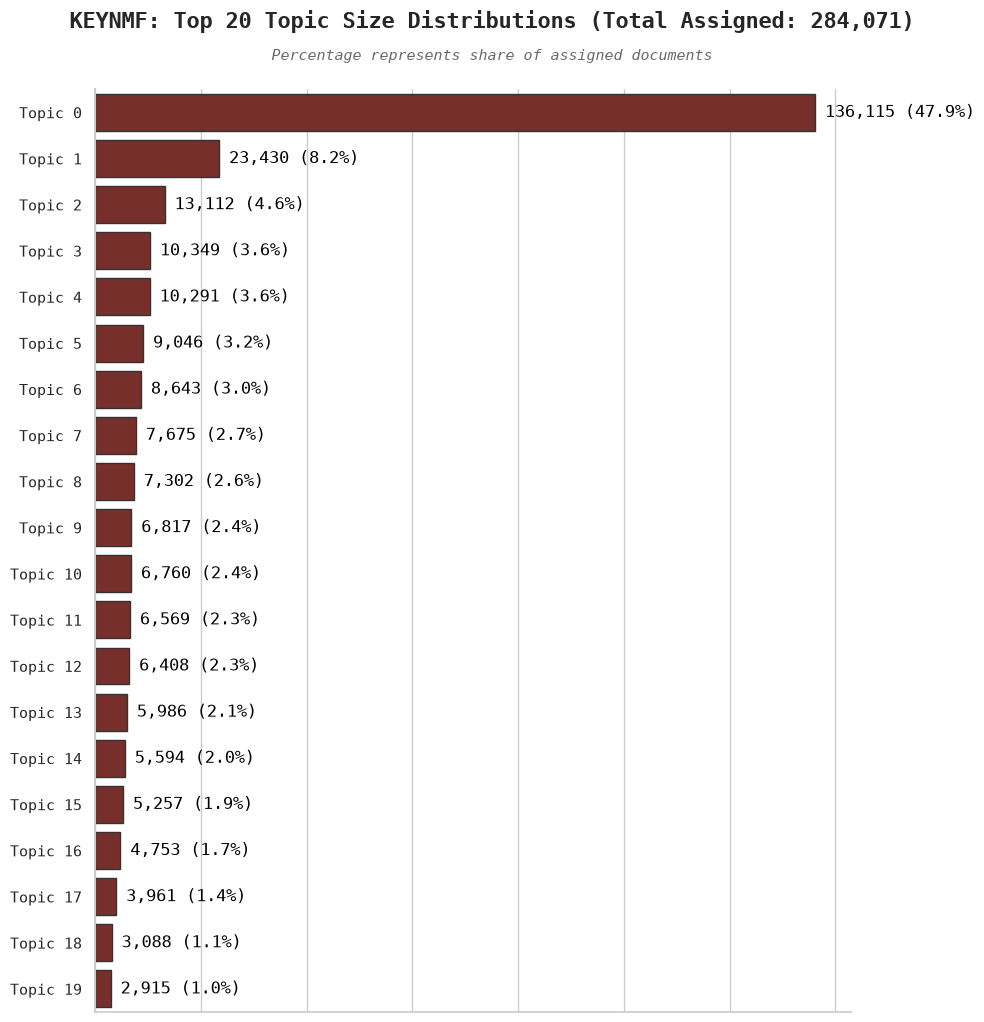

,topic,size,relative_share_%,absolute_share_%,top_words,examples
0,0,136115,47.9,47.7,"world, war, self, future, power, women, trump, time, story, health",What This Lecturer Shockingly Discovered After Watching Students For Years. Something About This Generation of Students || Is brand design moral? Can it be sustainable?. is design just 'acceptable' manipulation? || Case Study: How Flywheel Achieved $18-19 Million in ARR. The Story and Lessons from Leveraging Niche Marketing
1,1,23430,8.2,8.2,"new, substack, music, york, moon, news, live, video, community, city","OpenClaw takes China by storm: new picks from Scout. Plus: DeepSeek V4, dual-use export controls, and a landmark ruling for GenAI || Silver Academy, Pickaxe, SilverNATION under new administration. Restructuring & Cost Savings for Clients. For Immediate Release || Dream the Impossible Dream. What the New York Knicks' Historic Championship Can Teach Theatre Artists About Belief, Sacrifice, and Ensemble"
2,2,13112,4.6,4.6,"things, home, little, month, list, time, joy, learned, feel, 10","Strategic Fast-Forwarding. A random assortment of things on my mind. || 10 surprising things to buy on refill. Refilling cuts down on waste, and can save you money (yes, really) || Easter Let-Down. An honest look at spiritual highs, lows, and other odd things"
3,3,10349,3.6,3.6,"year, 2024, happy, january, 2023, time, birthday, old, years, season","A New Direction. Listen now | S5 Ep 1 - The Story of Destiny - how a lifelong dream to build a Selene 60 ocean trawler turned into a four year rebuilding project || Returning. on coming back to new york, surviving a year of uncertainty, and trusting the unfolding of my life || For Final Thoughts on Stress: 9 Blogs to Read. As we close out the year, I hope we all have had a chance to rest and recharge."
4,4,10291,3.6,3.6,"day, days, today, mother, valentine, morning, happy, time, night, father","17 Tons, and What Do You Get?. Another day older, if you're lucky || big dog's secrets to having a successful day. every meeting you have, prepare beforehand and bring something thoughtful to the meeting actively take notes during the meeting while trying to contribute || We Have 8 Days to Protect the US Post Office. And here's a prompt to help."
5,5,9046,3.2,3.2,"ai, agents, intelligence, future, agent, data, human, tech, tools, artificial","Claude Cowork is the best AI agent for finance. Ultimate Claude Cowork guide for finance & accounting: automating month-end close, reporting, and forecasting || 5 Questions that Slow Down a Runaway AI-Hyped Meeting. How to lead on purpose when urgency takes over the room || AI gets the joke. Maybe that's not funny…"
6,6,8643,3.0,3.0,"week, weekly, news, sunday, market, friday, weekend, monday, fashion, june","Is SPX Headed For All Time Highs? September 23rd Plan. As readers know, the theme for the past several months has been simple: buy the dips. The dips vary in size, speed, duration, and structure, but || Little Deuce Coupe. This is a bonus column. Tom returns later this week. || TL's Sunday Sports Notes | July 5. WWY(Ideas) | Trade Winds Blowing & Botching a Trade"
7,7,7675,2.7,2.7,"life, living, live, death, work, change, time, lessons, feel, learning",A 'Nice' Long Session. REAL Spanking Short Stories from The Life and Times of... || Your Parents Are Also Living Life for the First Time. Your parents are also living this life for the first time. || You can't plan a leap. On blowing up your life and learning to trust what you can't see.
8,8,7302,2.6,2.6,"2026, july, august, june, march, april, january, february, news, weekly","Friday Notes, February 27, 2026. Dear Friends — || Goose Patrol 2026. We have resumed our goose dogs patrols this season based on the success of last years program. || Ahead of the Curve: When Love Stops Performing. August 4, 2026: Why Shared Conscious Presence May Be the Sixth Love Language."
9,9,6817,2.4,2.4,"summer, august, season, july, june, spring, fall, solstice, autumn, hot",The 

In [17]:
plot_topic_distributions(results[name].doc_topics, len(results[name].topics), model_name=name)
inspect_model_topics(results[name], texts)

**Observations:**
- It scores highest on word-embedding coherence (0.487) and ties for highest on co-occurrence (c_npmi 0.106)
- However **topic 0 holds about 48% of all posts**, a catch-all of broad words: *world, war, self, future, power, women, trump, time*.
- Topic diversity is the lowest (0.705): *time*, *happy* and *new* recur across topics. 
- Similar to NMF, several topics focus on format, calendar and occasions, such as years and birthdays, or *day, mother, valentine, morning*, rather than subject matter.
- Its centroid similarity difference (centroid_sim_diff of 0.044) is lower than BERTopic, meaning the clusters are less tight. However, it is still higher than both NMF and LDA.

**Key Takeaways.**
- Similar to NMF, the topics keywords are very high level and generic rather than interesting or specific.
- Unlike standard NMF, KeyNMF does not require a document to contain the exact topic keywords to be grouped there.
- For example, Topic 3 has generic keywords (*things, home, little, month, list, time, joy, learned, feel, 10*), yet it picks up "Easter Let-Down. An honest look at spiritual highs, lows, and other odd things."
- Even though the topic keywords seem dull, the actual documents grouped under them are much more accurate.

## 5. Side by Side Comparison

All four models, the same data, the same metrics. One seed, so treat small gaps as ties.

In [18]:
default_metrics_df = pd.DataFrame(metrics.values()).set_index("model")

default_metrics_df.drop(columns=[c for c in default_metrics_df if c.endswith("_per_topic")])

,seed,runtime_s,runtime_m,n_topics,topic_diversity,outlier_rate,largest_topic_size,median_topic_size,smallest_topic_size,largest_topic_relative_%,median_topic_relative_%,smallest_topic_relative_%,largest_topic_absolute_%,median_topic_absolute_%,smallest_topic_absolute_%,n_tiny_topics,coherence_words_expected,coherence_words_found,coherence_word_coverage,coherence_n_topics_scored,coherence_c_v,coherence_c_npmi,wec,wec_n_topics_scored,wec_word_coverage,centroid_sim,centroid_sim_topic_mean,centroid_sim_chance,centroid_sim_diff,silhouette
model,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
nmf,0,39.2,0.7,20,0.790,0.000,130617,7705.0,5123,45.773,2.700,1.795,45.756,2.699,1.795,0,200,193,0.965,20,0.567,0.105,0.478,20,0.995,0.367,0.396,0.336,0.031,-0.036
lda,0,229.7,3.8,20,0.975,0.005,28961,12310.5,7118,10.192,4.332,2.505,10.145,4.312,2.493,0,200,197,0.985,20,0.478,0.062,0.434,20,0.995,0.365,0.356,0.336,0.029,-0.019
bertopic,0,162.6,2.7,20,0.955,0.538,28644,3812.0,156,21.732,2.892,0.118,10.034,1.335,0.055,0,200,197,0.985,20,0.484,0.070,0.393,20,0.985,0.417,0.456,0.331,0.086,0.009
keynmf,0,77.3,1.3,20,0.705,0.005,136115,6788.5,2915,47.916,2.390,1.026,47.682,2.378,1.021,0,200,194,0.970,20,0.562,0.106,0.487,20,0.990,0.380,0.450,0.336,0.044,-0.046


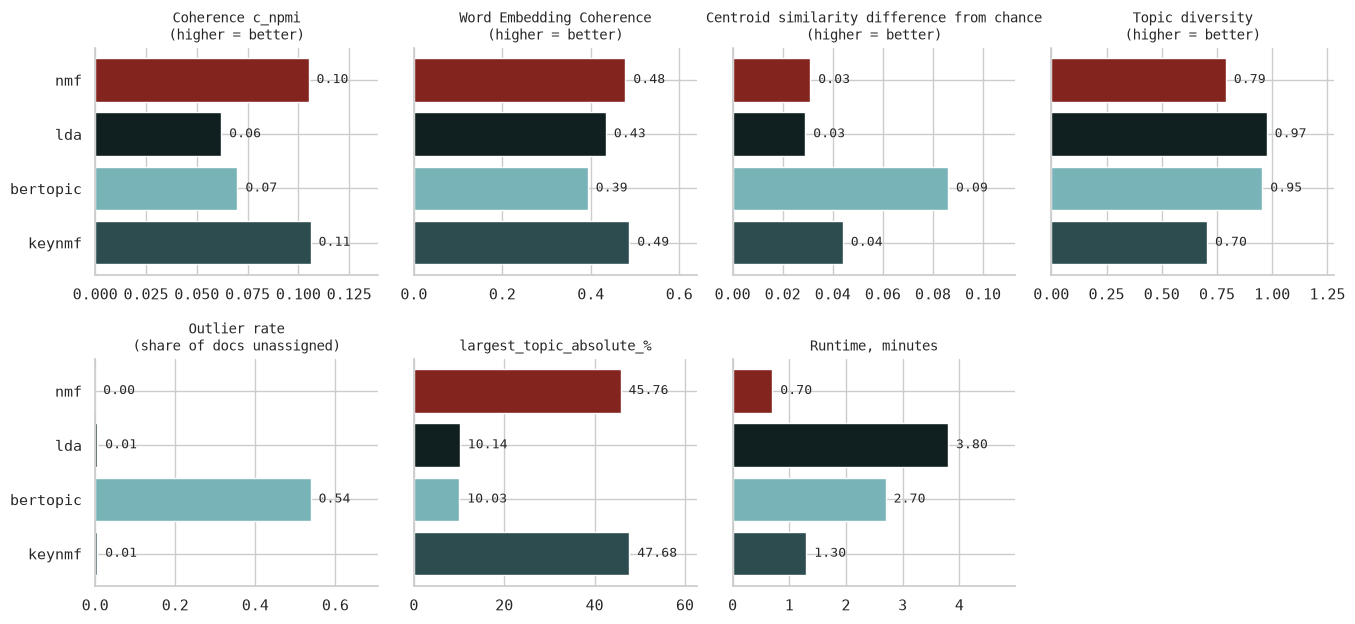

In [19]:
KEY_METRICS = ("coherence_c_npmi", "wec", "centroid_sim_diff", "topic_diversity",
               "outlier_rate", "largest_topic_absolute_%", "runtime_m")
plot_model_comparison(default_metrics_df, metrics=KEY_METRICS)


In [20]:
table = compare_top_topics(results, n=10, n_words=10)
with pd.option_context("display.max_colwidth", None):
    display(table.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,nmf,lda,bertopic,keynmf
size rank,,,,
1,"45.8% | people, ve, work, way, make, years, let, art, right, think","10.2% | ai, business, social, future, system, company, human, product, tech, strategy","21.7% | poem, episode, podcast, music, moon, new, live, poetry, recording, video","47.9% | world, war, self, future, power, women, trump, time, story, health"
2,"5.3% | 2026, september, august, july, newsletter, june, april, weekly, march, update","8.8% | year, thing, good, week, new, old, bad, time, happy, lot","20.7% | art, life, love, 2026, time, mother, grief, 2025, don, like","8.2% | new, substack, music, york, moon, news, live, video, community, city"
3,"4.9% | book, writing, read, reading, books, club, review, chapter, write, month","8.5% | life, god, chapter, child, heart, truth, family, way, light, joy","8.7% | iran, war, israel, black, trump, ukraine, women, russia, gaza, election","4.6% | things, home, little, month, list, time, joy, learned, feel, 10"
4,"3.5% | new, york, welcome, moon, happy, city, series, plus, newsletter, music","7.5% | day, book, post, new, substack, writing, morning, reading, club, writer","7.8% | recipe, food, wine, chicken, salad, coffee, recipes, cake, dinner, meal","3.6% | year, 2024, happy, january, 2023, time, birthday, old, years, season"
5,"3.1% | week, weekly, news, 26, 10, friday, fashion, sunday, market, newsletter","6.6% | summer, newsletter, season, week, weekly, edition, news, game, july, september","6.9% | substack, newsletter, writing, book, books, media, social, read, write, new","3.6% | day, days, today, mother, valentine, morning, happy, time, night, father"
6,"3.1% | ai, use, data, human, future, agents, age, intelligence, tools, building","6.0% | new, city, trump, party, public, political, law, government, york, class","6.1% | christmas, birthday, year, summer, letter, day, happy, new, love, week","3.2% | ai, agents, intelligence, future, agent, data, human, tech, tools, artificial"
7,"3.0% | year, 2025, happy, old, end, 2024, review, books, january, best","5.0% | art, work, power, room, reality, fear, voice, beauty, john, quiet","5.6% | market, crypto, bitcoin, money, climate, portfolio, trading, canada, stock, stocks","3.0% | week, weekly, news, sunday, market, friday, weekend, monday, fashion, june"
8,"2.9% | world, cup, war, end, change, real, living, trump, america, place","4.7% | love, woman, man, friend, health, letter, space, relationship, dear, real","5.3% | ai, data, intelligence, agents, artificial, human, agent, use, work, new","2.7% | life, living, live, death, work, change, time, lessons, feel, learning"
9,"2.8% | life, living, changed, want, death, change, real, lessons, update, lived","4.7% | self, body, poem, video, school, mind, live, creative, kid, point","4.6% | china, paris, india, japan, travel, chinese, africa, new, italy, france","2.6% | 2026, july, august, june, march, april, january, february, news, weekly"


**What the numbers show**

| | c_npmi | WEC | tightness above chance | diversity | outliers | relative largest topic | runtime |
|---|---|---|---|---|---|---|---|
| NMF | **0.105** | 0.478 | 0.031 | 0.790 | 0.0% | **45.8%** | 0.6 min |
| LDA | 0.063 | 0.436 | 0.029 | **0.975** | 0.5% | 10.2% | 3.7 min |
| BERTopic | 0.070 | 0.393 | **0.086** | 0.955 | **53.8%** | 21.8% | 2.8 min |
| KeyNMF | **0.106** | **0.487** | 0.044 | 0.705 | 0.5% | **47.9%** | 1.2 min |

1. **No model dominates across the board.** Each model’s strongest score comes with a clear trade-off.
2. **The best coherence comes with a catch-all topic.** NMF and KeyNMF score highest on both word-level measures, and also have a topic holding about half the posts. A topic of generic words co-occurs with many others, so the coherence score might be inflated. A high coherence score might not necessarily mean semantically meaningful or useful topics.
3. **BERTopic leads in document tightness**, aided by semantic clustering, though this advantage is heavily driven by discarding 54% of the posts.
4. **The size distributions differ most**: LDA is nearly flat, NMF and KeyNMF start near 48%, BERTopic has a long tail of tiny topics.

**Iterations.** 
- **Standardised word counts for coherence**: The initial coherence scores were not comparable because the scoring function truncated every topic to match the shortest one. Models were evaluated on anywhere from 2 to 8 words per topic, which artificially boosted NMF since it was scored on only 4 words. To fix this, every topic is now evaluated on a fixed set of 10 words, alongside explicit reporting on how many words and topics were scored.
- **Dropped redundant metrics**: `coherence_c_v` ranks the models in the very similar order as `c_npmi` (save for a 0.001 tie at the top), while silhouette scores sit between -0.05 and 0.01 across all models. Because neither adds a distinct signal, both were excluded.
- **Excluded ground-truth labels**: No metric relies on true labels, as the category column is generated by a loose regex (see notebook 00).


## 6. Takeaways

**Problems at default settings, and next steps**

| Problem | Evidence | Next step (notebook 02) |
|---|---|---|
| A catch-all topic (NMF, KeyNMF) | about 46% and 48% of all posts in topic 0, generic words | Sweep the number of topics. Re-score coherence with that topic excluded. |
| Half the posts unassigned (BERTopic) | 53.8% outliers and 6 of 20 topics under 1% of classified posts | Sweep `min_cluster_size`, then try outlier reduction. Compare models on the same posts. |
| Tokenisation leftovers | *ve*, *don* in topic words | Use a token pattern that keeps contractions together, or extend the stop list. |
| One seed, no noise estimate | small gaps on several metrics | Three to five seeds before claiming any ranking. |
| Calendar and format topics in every model | month names, years, "weekly" and "newsletter"; 82% of posts from 2025 to 2026 | Decide: remove month and year tokens, or keep them and treat them as a finding. |

**Key Takeaways:** 
- On automated metrics alone, NMF and KeyNMF look like the top choices, but reading the actual topics rules both out.
- Nearly half of all posts sit inside a single catch-all topic, while most remaining topics reflect generic words, publishing formats, and calendar dates rather than actual subjects.
- LDA and BERTopic both find much more meaningful themes, though each has a clear trade-off: LDA has the weakest word co-occurrence, while BERTopic leaves roughly half of all posts unassigned.
- This gap between automated scores and manual reading is common in real-world topic modelling projects, and directly guides the tuning strategy.


## 7. Export for the Streamlit app

- Small, aggregated summary tables only.
- **Anonymised sample posts (without author names or publication identifiers)** are exported, ensuring all artefacts are safe to commit.

In [21]:
import json

ARTEFACTS_PATH = Path("../artefacts/01_models_default_settings")
ARTEFACTS_PATH.mkdir(exist_ok=True)
print("Artefacts directory:", ARTEFACTS_PATH)

Artefacts directory: ../artefacts/01_models_default_settings

In [24]:
# Export setup information 
setup_path = ARTEFACTS_PATH / "model_setup.json"
setup = {
    "models_compared": int(len(results)),
    "modelled_posts": int(len(texts)),
    "modelled_publications": int(corpus["publication_domain"].nunique()),
    "modelled_fraction": float(SAMPLE_FRACTION),  
    "target_num_topics": int(configs["nmf"]["n_topics"]),
    "top_n_words_extracted": int(configs["nmf"]["top_n_words"]),
    "top_n_words_scored": int(TOP_N_SCORED),
    "seed": int(SEED),
    "n_coherence_reference_docs": int(N_COHERENCE_REFERENCE_DOCS),
    "reference_embeddings_model": str(REFERENCE_EMBEDDINGS_MODEL),
    "word_vectors": str(WORD_VECTORS),
}

setup_path.write_text(json.dumps(setup, indent=2), encoding="utf-8")

# Export default metrics
default_metrics_df.drop(
    columns=[c for c in default_metrics_df if c.endswith("_per_topic")]
             ).to_csv(ARTEFACTS_PATH / "model_default_metrics.csv")

# Export topics words for each model
# json.dump({n: r.topics for n, r in results.items()}, 
#           open(ARTEFACTS_PATH / "model_default_topics.json", "w"), indent=2)

# Export topic cards for each model
cards = []
for model_name, result in results.items():
    card = inspect_model_topics(result, texts)
    cards.append(card.assign(model=model_name))
cards = pd.concat(cards, ignore_index=True)
cards = cards[["model"] + [c for c in cards.columns if c != "model"]]
cards.to_csv(ARTEFACTS_PATH / "model_default_topic_cards.csv", index=False)

print("Exported", len(cards), "topic rows for", cards["model"].nunique(), "models")
print("Exported", len(list(ARTEFACTS_PATH.glob("*"))), "files to", ARTEFACTS_PATH)

Exported 80 topic rows for 4 models

Exported 3 files to ../artefacts/01_models_default_settings